# Projet EuroSAT · Sujet 1 : classer les paysages avec les 13 bandes du satellite

**Groupe :** *(vos trois prénoms)*

## Sujet

EuroSAT rassemble 27 000 images du satellite Sentinel-2 de l'Agence spatiale européenne, de 64×64 pixels, réparties en 10 types de paysages. Chaque image comporte **13 bandes spectrales**, dont plusieurs dans l'infrarouge, invisible à l'œil.

**Mission.** Exploiter les 13 bandes pour classer les paysages, et montrer ce que les bandes invisibles apportent.

**Approche.** Un ResNet pré-entraîné sur des images en couleurs (par exemple celui de `torchvision`), dont on **modifie la première couche** pour qu'il accepte 13 canaux au lieu de 3, puis **fine-tuning**. A vous de voir lequel.

**Critère de réussite.** L'accuracy et le F1 de chaque classe sur le jeu de test, et les classes qui profitent le plus des bandes supplémentaires.

**Baseline.** Le même modèle, avec le même protocole, entraîné uniquement sur les 3 bandes rouge, verte et bleue.

## Consignes

- **Tout faire dans ce notebook.**
- **Sans IA** : pas de Copilot, de ChatGPT ni d'autre assistant. Vous en êtes capables ! Si besoin, venez me voir.
- **À 15 h, vous présenterez vos résultats** :
  1. Présenter l'objectif
  2. La stratégie que vous avez choisie
  3. Expliquer les différentes étapes que vous avez dû faire
  4. Expliquer les problèmes rencontrés
  5. Présenter vos résultats
  6. Les analyser et les critiquer
- **Comparez les performances obtenues à une baseline** (voir le sujet ci-dessus).

## Récupérer les données

La cellule ci-dessous télécharge la version **13 bandes** d'EuroSAT (une seule fois), puis charge un sous-échantillon en mémoire :

| Variable | Contenu |
|---|---|
| `X_train`, `X_val`, `X_test` | images, tableaux numpy `uint16` de forme `(N, 13, 64, 64)` : valeurs brutes du satellite, **à normaliser vous-mêmes** |
| `y_train`, `y_val`, `y_test` | classe de chaque image, entier de 0 à 9 |
| `CLASSES` | nom de chaque classe |
| `BANDES`, `RVB` | nom des 13 bandes ; indices des bandes rouge, verte et bleue (`X[:, RVB]` donne l'image en couleurs) |

**Attention : l'archive pèse environ 2 Go.** Si l'enseignant vous fournit le fichier `EuroSATallBands.zip`, copiez-le dans le dossier `data/` avant de lancer la cellule : il ne sera pas re-téléchargé.

Par défaut, la fonction `charger` garde 300 images par classe pour le train, 100 pour la validation et 200 pour le test. Vous pouvez changer ces nombres (`None` = toutes les images).

Vos machines n'ont pas de GPU : mettez votre code au point sur un petit sous-échantillon, mesurez le temps d'une époque, puis seulement passez à plus de données.

In [1]:
%pip install -q numpy matplotlib requests tifffile imagecodecs

# ----- Outil de téléchargement (rien à modifier) -----
import os, hashlib
import requests

def telecharger(url, chemin, md5=None, sha256=None):
    """Télécharge url dans chemin, sauf si le fichier est déjà là."""
    if os.path.exists(chemin):
        print(f"Déjà présent : {chemin}")
        return
    os.makedirs(os.path.dirname(chemin), exist_ok=True)
    print(f"Téléchargement de {os.path.basename(chemin)} :", end=" ")
    empreinte = hashlib.md5() if md5 else hashlib.sha256()
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        recu, palier = 0, 0
        with open(chemin + ".part", "wb") as f:
            for bloc in r.iter_content(chunk_size=1 << 20):
                f.write(bloc)
                empreinte.update(bloc)
                recu += len(bloc)
                while total and recu * 100 // total >= palier:
                    print(f"{palier} %", end=" ")
                    palier += 10
    print()
    attendu = md5 or sha256
    if attendu and empreinte.hexdigest() != attendu:
        os.remove(chemin + ".part")
        raise RuntimeError("Fichier corrompu : relancez la cellule.")
    os.replace(chemin + ".part", chemin)

# ----- Chargement des données -----

import io, zipfile
import numpy as np
import tifffile

DATA_DIR = "data"
CLASSES_EN = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
              "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
CLASSES = ["culture annuelle", "forêt", "végétation herbacée", "autoroute", "zone industrielle",
           "pâturage", "culture permanente", "zone résidentielle", "rivière", "mer ou lac"]
BANDES = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B09", "B10", "B11", "B12", "B8A"]
RVB = [3, 2, 1]   # B04 = rouge, B03 = vert, B02 = bleu

# Images 13 bandes (environ 2 Go)
ARCHIVE = os.path.join(DATA_DIR, "EuroSATallBands.zip")
telecharger("https://huggingface.co/datasets/torchgeo/eurosat/resolve/1ce6f1bfb56db63fd91b6ecc466ea67f2509774c/EuroSATallBands.zip",
            ARCHIVE, sha256="751f070f9bffa2eed48b24ca2dd0b02959280c08837e8c9a5532a67ba611df59")

# Découpage officiel train / validation / test (le même que la bibliothèque torchgeo)
URL_SPLITS = "https://huggingface.co/datasets/torchgeo/eurosat/resolve/1ce6f1bfb56db63fd91b6ecc466ea67f2509774c/"
SPLITS = {}
for split in ["train", "val", "test"]:
    fichier = os.path.join(DATA_DIR, f"eurosat-{split}.txt")
    telecharger(URL_SPLITS + f"eurosat-{split}.txt", fichier)
    with open(fichier) as f:
        SPLITS[split] = [os.path.splitext(os.path.basename(ligne.strip()))[0] for ligne in f if ligne.strip()]

# Les images sont lues directement dans l'archive, sans la décompresser
archive = zipfile.ZipFile(ARCHIVE)
MEMBRES = {os.path.splitext(os.path.basename(m))[0]: m for m in archive.namelist() if m.endswith(".tif")}

def _choisir(split, n_par_classe, graine):
    """Noms des images d'un split, éventuellement limités à n_par_classe images par classe."""
    noms = [n for n in SPLITS[split] if n in MEMBRES]
    if n_par_classe is None:
        return noms
    rng = np.random.default_rng(graine)
    garde = []
    for c in CLASSES_EN:
        noms_c = [n for n in noms if n.rsplit("_", 1)[0] == c]
        rng.shuffle(noms_c)
        garde += noms_c[:n_par_classe]
    return garde

def charger(split, n_par_classe=None, graine=0):
    """Renvoie X (N, 13, 64, 64) en uint16 et y (N,) pour le split 'train', 'val' ou 'test'."""
    noms = _choisir(split, n_par_classe, graine)
    X = np.empty((len(noms), 13, 64, 64), dtype=np.uint16)
    y = np.empty(len(noms), dtype=np.int64)
    for i, nom in enumerate(noms):
        image = tifffile.imread(io.BytesIO(archive.read(MEMBRES[nom])))
        if image.shape[-1] == 13:            # (64, 64, 13) -> (13, 64, 64)
            image = image.transpose(2, 0, 1)
        X[i] = image
        y[i] = CLASSES_EN.index(nom.rsplit("_", 1)[0])
    return X, y

X_train, y_train = charger("train", n_par_classe=300)
X_val,   y_val   = charger("val",   n_par_classe=100)
X_test,  y_test  = charger("test",  n_par_classe=200)


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Téléchargement de EuroSATallBands.zip : 0 % 10 % 20 % 30 % 40 % 50 % 60 % 70 % 80 % 90 % 100 % 
Téléchargement de eurosat-train.txt : 
Téléchargement de eurosat-val.txt : 
Téléchargement de eurosat-test.txt : 


Taille complète des splits : {'train': 16200, 'val': 5400, 'test': 5400}
Chargé en mémoire : train (3000, 13, 64, 64) | val (1000, 13, 64, 64) | test (2000, 13, 64, 64)

Classe                  train    val   test
0  culture annuelle       300    100    200
1  forêt                  300    100    200
2  végétation herbacée    300    100    200
3  autoroute              300    100    200
4  zone industrielle      300    100    200
5  pâturage               300    100    200
6  culture permanente     300    100    200
7  zone résidentielle     300    100    200
8  rivière                300    100    200
9  mer ou lac             300    100    200

Valeur moyenne de chaque bande (train) :
{'B01': 1357, 'B02': 1121, 'B03': 1046, 'B04': 946, 'B05': 1206, 'B06': 2032, 'B07': 2410, 'B08': 2337, 'B09': 744, 'B10': 12, 'B11': 1833, 'B12': 1124, 'B8A': 2639}


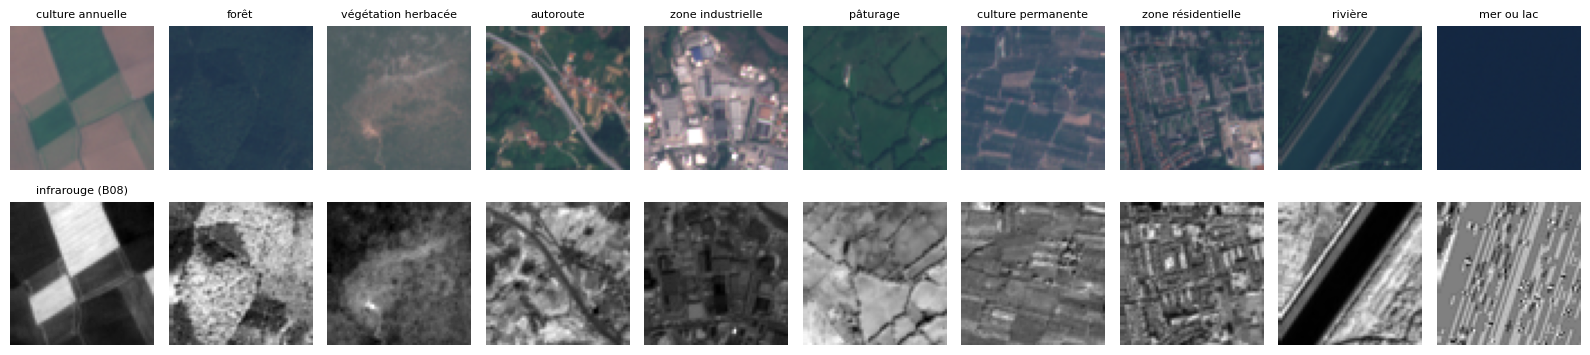

In [2]:
import matplotlib.pyplot as plt

print("Taille complète des splits :", {s: len(v) for s, v in SPLITS.items()})
print("Chargé en mémoire : train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)
print()
print(f"{'Classe':<22}{'train':>7}{'val':>7}{'test':>7}")
for c, nom in enumerate(CLASSES):
    print(f"{c}  {nom:<19}{(y_train == c).sum():>7}{(y_val == c).sum():>7}{(y_test == c).sum():>7}")
print()
print("Valeur moyenne de chaque bande (train) :")
print({b: int(m) for b, m in zip(BANDES, X_train.mean(axis=(0, 2, 3)))})

# Première ligne : l'image en couleurs. Seconde ligne : la bande B08 (proche infrarouge).
fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
for c in range(10):
    i = np.flatnonzero(y_train == c)[0]
    rvb = np.clip(X_train[i, RVB].transpose(1, 2, 0) / 3000, 0, 1)
    axes[0, c].imshow(rvb)
    axes[0, c].set_title(CLASSES[c], fontsize=8)
    axes[1, c].imshow(X_train[i, BANDES.index("B08")], cmap="gray")
    for ax in axes[:, c]:
        ax.axis("off")
axes[1, 0].set_title("infrarouge (B08)", fontsize=8)
plt.tight_layout()
plt.show()

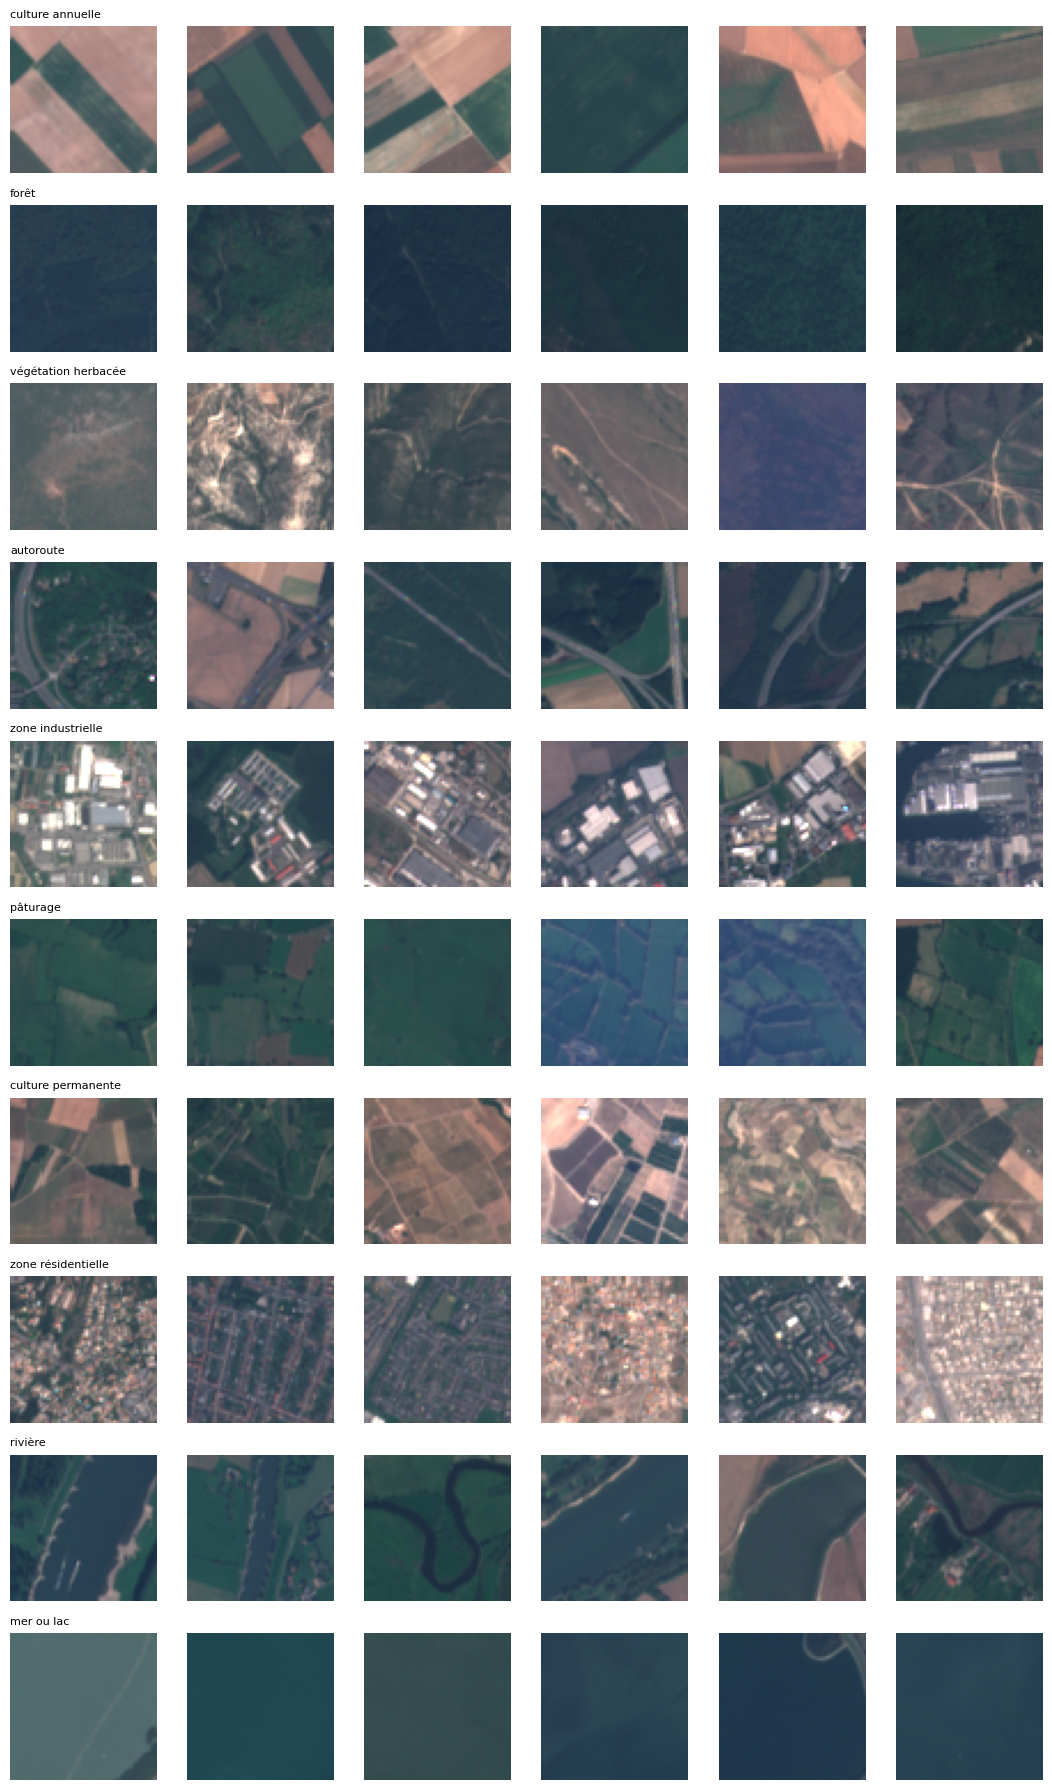

In [3]:
N_PAR_CLASSE = 6
fig, axes = plt.subplots(len(CLASSES), N_PAR_CLASSE, figsize=(1.8 * N_PAR_CLASSE, 1.8 * len(CLASSES)))
rng = np.random.default_rng(0)
for c in range(len(CLASSES)):
    indices = np.flatnonzero(y_train == c)
    choisis = rng.choice(indices, size=min(N_PAR_CLASSE, len(indices)), replace=False)
    for j in range(N_PAR_CLASSE):
        ax = axes[c, j]
        ax.axis("off")
        if j < len(choisis):
            ax.imshow(np.clip(X_train[choisis[j], RVB].transpose(1, 2, 0) / 3000, 0, 1))
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc="left")
plt.tight_layout()
plt.show()


## Votre travail